### Procesamiento de Lenguaje Natural I
# **Desafío 1**



In [1]:
%pip install numpy scikit-learn

Looking in indexes: https://pypi.artifacts.furycloud.io/simple
Note: you may need to restart the kernel to use updated packages.


### Vectorización de texto y modelo de clasificación Naïve Bayes con el dataset 20 newsgroups

In [2]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.metrics import f1_score

Utilizamos **20newsgroups** por ser un dataset clásico de NLP ya viene incluido y formateado en sklearn

In [3]:
from sklearn.datasets import fetch_20newsgroups
import numpy as np

## Carga de datos

Cargamos los datos (ya separados de forma predeterminada en train y test)

El dataset 20 Newsgroups contiene aproximadamente 18 000 publicaciones de grupos de noticias distribuidas en 20 temas. Está dividido en dos subconjuntos: uno para entrenamiento (train set) y otro para pruebas (test set).

In [4]:
newsgroups_train = fetch_20newsgroups(subset='train', remove=('headers', 'footers', 'quotes'))
newsgroups_test = fetch_20newsgroups(subset='test', remove=('headers', 'footers', 'quotes'))

## Vectorización

Instanciamos un vectorizador.

Podemos ver diferentes parámetros de instanciación en la documentación de sklearn https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html

In [5]:
tfidfvect = TfidfVectorizer()

En el atributo `data` accedemos al texto

In [6]:
print(newsgroups_train.data[1])

A fair number of brave souls who upgraded their SI clock oscillator have
shared their experiences for this poll. Please send a brief message detailing
your experiences with the procedure. Top speed attained, CPU rated speed,
add on cards and adapters, heat sinks, hour of usage per day, floppy disk
functionality with 800 and 1.4 m floppies are especially requested.

I will be summarizing in the next two days, so please add to the network
knowledge base if you have done the clock upgrade and haven't answered this
poll. Thanks.


Con la interfaz habitual de sklearn podemos ajustar el vectorizador (obtener el vocabulario y calcular el vector IDF) y transformar directamente los datos.

Podemos denominar `X_train` como la matriz documento-término.

In [7]:
X_train = tfidfvect.fit_transform(newsgroups_train.data)

Recordemos que las vectorizaciones por conteos son de tipo sparse, por ello sklearn convenientemente devuelve los vectores de documentos como matrices de tipo sparse.

In [8]:
print(type(X_train))
print(f'shape: {X_train.shape}')
print(f'Cantidad de documentos: {X_train.shape[0]}')
print(f'Tamaño del vocabulario (dimensionalidad de los vectores): {X_train.shape[1]}')

<class 'scipy.sparse._csr.csr_matrix'>
shape: (11314, 101631)
Cantidad de documentos: 11314
Tamaño del vocabulario (dimensionalidad de los vectores): 101631


Una vez ajustado el vectorizador, podemos acceder a atributos como el vocabulario aprendido. Es un diccionario que va de términos a índices.

El índice es la posición en el vector de documento.

In [9]:
tfidfvect.vocabulary_['car']

25775

Probamos con una palbra que no está en el documento.

In [10]:
# tfidfvect.vocabulary_['cocoliso']

Es muy útil tener el diccionario opuesto que va de índices a términos

In [11]:
idx2word = {v: k for k,v in tfidfvect.vocabulary_.items()}

En `y_train` guardamos los targets que son enteros

In [12]:
y_train = newsgroups_train.target
y_train[:10]

array([ 7,  4,  4,  1, 14, 16, 13,  3,  2,  4])

Hay 20 clases correspondientes a los 20 grupos de noticias

In [13]:
print(f'clases {np.unique(newsgroups_test.target)}')
newsgroups_test.target_names

clases [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]


['alt.atheism',
 'comp.graphics',
 'comp.os.ms-windows.misc',
 'comp.sys.ibm.pc.hardware',
 'comp.sys.mac.hardware',
 'comp.windows.x',
 'misc.forsale',
 'rec.autos',
 'rec.motorcycles',
 'rec.sport.baseball',
 'rec.sport.hockey',
 'sci.crypt',
 'sci.electronics',
 'sci.med',
 'sci.space',
 'soc.religion.christian',
 'talk.politics.guns',
 'talk.politics.mideast',
 'talk.politics.misc',
 'talk.religion.misc']

## Similaridad de documentos

Veamos similaridad de documentos. Tomemos algún documento

In [14]:
idx = 4811
print(newsgroups_train.data[idx])

THE WHITE HOUSE

                  Office of the Press Secretary
                   (Pittsburgh, Pennslyvania)
______________________________________________________________
For Immediate Release                         April 17, 1993     

             
                  RADIO ADDRESS TO THE NATION 
                        BY THE PRESIDENT
             
                Pittsburgh International Airport
                    Pittsburgh, Pennsylvania
             
             
10:06 A.M. EDT
             
             
             THE PRESIDENT:  Good morning.  My voice is coming to
you this morning through the facilities of the oldest radio
station in America, KDKA in Pittsburgh.  I'm visiting the city to
meet personally with citizens here to discuss my plans for jobs,
health care and the economy.  But I wanted first to do my weekly
broadcast with the American people. 
             
             I'm told this station first broadcast in 1920 when
it reported that year's presidential elec

Medimos la similaridad coseno con todos los documentos de train

In [15]:
cossim = cosine_similarity(X_train[idx], X_train)[0]

Podemos ver los valores de similaridad ordenados de mayor a menor

In [16]:
np.sort(cossim)[::-1]

array([1.        , 0.70930477, 0.67474953, ..., 0.        , 0.        ,
       0.        ], shape=(11314,))

Después vemos a qué documentos corresponden

In [17]:
np.argsort(cossim)[::-1]

array([ 4811,  6635,  4253, ...,  1534, 10055,  4750], shape=(11314,))

Obtenemos los 5 documentos más similares:

In [18]:
mostsim = np.argsort(cossim)[::-1][1:6]
print(mostsim)

[6635 4253 3596 4271 3746]


El documento original pertenece a la clase:

In [19]:
newsgroups_train.target_names[y_train[idx]]

'talk.politics.misc'

Revisamos las clases de los 5 más similares:

In [20]:
for i in mostsim:
  print(newsgroups_train.target_names[y_train[i]])

talk.politics.misc
talk.politics.misc
talk.politics.misc
talk.politics.misc
talk.politics.misc


### Modelo de clasificación Naïve Bayes

Instanciamos el modelo de clasificación Naive Bayes y lo entrenamos con sklearn

In [21]:
clf = MultinomialNB()
clf.fit(X_train, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](20,)","[480.,584.,591.,...,564.,465.,377.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](20,)","[-3.16,-2.96,-2.95,...,-3. ,-3.19,-3.4 ]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](20,)","[ 0, 1, 2,...,17,18,19]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](20, 101631)","[[0. ,0.94,0. ,...,0. ,0. ,0. ], [1.39,0.6 ,0. ,...,0. ,0. ,0. ], [0.95,0.14,0. ,...,0. ,0. ,0. ], ..., [0.42,2.9 ,0.04,...,0. ,0. ,0. ], [0.61,1.36,0. ,...,0. ,0. ,0. ], [0.03,0.38,0. ,...,0. ,0. ,0. ]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](20, 101631)","[[-11.56,-10.9 ,-11.56,...,-11.56,-11.56,-11.56], [-10.69,-11.1 ,-11.56,...,-11.56,-11.56,-11.56], [-10.9 ,-11.44,-11.57,...,-11.57,-11.57,-11.57], ..., [-11.22,-10.21,-11.54,...,-11.57,-11.57,-11.57], [-11.09,-10.7 ,-11.56,...,-11.56,-11.56,-11.56], [-11.53,-11.23,-11.56,...,-11.56,-11.56,-11.56]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,101631


Ya tenemos nuestro vectorizador ya ajustado en train, vectorizamos los textos
del conjunto de test.

In [22]:
X_test = tfidfvect.transform(newsgroups_test.data)
y_test = newsgroups_test.target
y_pred =  clf.predict(X_test)

El F1-score es una métrica adecuada para evaluar el desempeño de modelos de clasificación, especialmente cuando existe desbalance entre clases.

* El promediado macro calcula el promedio del F1-score de cada clase, otorgando el mismo peso a todas las clases.
* El promediado micro calcula las métricas de forma global considerando todas las predicciones; en problemas de clasificación multiclase suele ser equivalente a la accuracy, por lo que no es la mejor métrica cuando el dataset está desbalanceado.

In [23]:
f1_score(y_test, y_pred, average='macro')

0.5854345727938506

---

## **Consigna del Desafío 1**
**Cada experimento realizado debe estar acompañado de una explicación o interpretación de lo observado.**



**1. Vectorizar documentos**
* Tomar 5 documentos al azar y medir similaridad con el resto de los documentos.
Estudiar los 5 documentos más similares de cada uno analizar si tiene sentido
la similaridad según el contenido del texto y la etiqueta de clasificación.

**2. Construir un modelo de clasificación por prototipos (tipo zero-shot).**
* Clasificar los documentos de un conjunto de test comparando cada uno con todos los de entrenamiento y asignar la clase al label del documento del conjunto de entrenamiento con mayor similaridad.

**3. Entrenar modelos de clasificación Naïve Bayes para maximizar el desempeño de clasificación**

* F1-Score Macro en el conjunto de datos de test. Considerar cambiar parámetros
de instanciación del vectorizador y los modelos y probar modelos de Naïve Bayes Multinomial y ComplementNB.

**NO cambiar el hiperparámetro ngram_range de los vectorizadores**.

**4. Transponer la matriz documento-término.**
* De esa manera se obtiene una matriz término-documento que puede ser interpretada como una colección de vectorización de palabras.
* Estudiar ahora similaridad entre palabras tomando 5 palabras y estudiando sus 5 más similares.

**Elegir las palabras MANUALMENTE para evitar la aparición de términos poco interpretables**.


### Punto 1)

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import f1_score, accuracy_score
from sklearn.neighbors import NearestNeighbors

# Exploración reproducible: 5 documentos de test contra el resto de test.
rng = np.random.default_rng(42)
indices_aleatorios = rng.choice(len(newsgroups_test.data), size=5, replace=False)
X_test_muestra = X_test[indices_aleatorios]
similitudes = cosine_similarity(X_test_muestra, X_test)

for fila, indice in enumerate(indices_aleatorios):
    sims = similitudes[fila].copy()
    sims[indice] = -np.inf  # excluir el propio documento
    vecinos = np.argsort(sims)[::-1][:5]
    etiqueta = newsgroups_test.target_names[newsgroups_test.target[indice]]
    texto = " ".join(newsgroups_test.data[indice].split())
    print(f"\nDocumento test {indice} | etiqueta real: {etiqueta}")
    print(f"Texto: {texto[:350] or '[vacío luego del preprocesamiento]'}")
    for rango, vecino in enumerate(vecinos, start=1):
        etiqueta_vecino = newsgroups_test.target_names[newsgroups_test.target[vecino]]
        texto_vecino = " ".join(newsgroups_test.data[vecino].split())
        coincide = newsgroups_test.target[vecino] == newsgroups_test.target[indice]
        print(
            f"  {rango}. doc {vecino} | coseno={sims[vecino]:.3f} | "
            f"{etiqueta_vecino} | misma etiqueta={coincide} | "
            f"{texto_vecino[:180] or '[vacío]'}"
        )

# F1 de un clasificador 1-NN TF-IDF: cada documento de test busca
# su vecino más cercano exclusivamente dentro de train.
vecino_train = NearestNeighbors(n_neighbors=1, metric="cosine", algorithm="brute")
vecino_train.fit(X_train)
distancias_nn, indices_nn = vecino_train.kneighbors(X_test)
y_pred_1nn = newsgroups_train.target[indices_nn[:, 0]]
y_test = newsgroups_test.target
print("\n1-NN TF-IDF, test contra train")
print(f"F1 macro:    {f1_score(y_test, y_pred_1nn, average='macro'):.3f}")
print(f"F1 weighted: {f1_score(y_test, y_pred_1nn, average='weighted'):.3f}")
print(f"F1 micro:    {f1_score(y_test, y_pred_1nn, average='micro'):.3f}")
print(f"Accuracy:    {accuracy_score(y_test, y_pred_1nn):.3f}")

**¿Qué se ve al comparar los textos y las etiquetas?** En varios casos, los vecinos más cercanos hablan del mismo tema que el documento original y además tienen la misma etiqueta. Por ejemplo, en `comp.windows.x` aparecen consultas y respuestas sobre eventos, botones y ventanas de X; ahí la similitud parece razonable. En `talk.politics.guns`, también se acercan mensajes del mismo debate y hasta aparece el mismo autor, así que parte de la similitud puede venir del estilo o de frases repetidas, además del tema.

No siempre coinciden texto y etiqueta. Un documento de `sci.electronics` quedó cerca de textos de `sci.space`: comparten palabras relacionadas con temperatura, pero el tema de fondo cambia. Eso muestra que TF-IDF encuentra palabras en común, aunque no necesariamente entienda de qué trata el mensaje. También hay documentos vacíos después de quitar encabezados, firmas y citas; si el texto está vacío, que sus vecinos tengan coseno 0 no nos dice nada útil.

El F1 no lo sacamos de estos cinco ejemplos: son pocos para evaluar el clasificador. Para tener una medida más representativa, cada documento de test busca su vecino más cercano en train. Con TF-IDF y 1-NN, el F1 macro es **0,505** y el F1 weighted **0,513**. O sea, la etiqueta del vecino suele orientar, pero todavía se equivoca bastante. Como referencia, Naïve Bayes con la configuración por defecto da F1 macro **0,585** (Multinomial) y **0,693** (Complement); después se pueden comparar esos resultados con los ajustes del punto 3.

### Punto 2)

In [28]:
# Si hace falta:
# pip install sentence-transformers

from sentence_transformers import SentenceTransformer
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score

# Modelo preentrenado; se descarga de Hugging Face la primera vez
modelo = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

# Convertir los documentos a embeddings
embeddings_train = modelo.encode(
    newsgroups_train.data,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True,
)

embeddings_test = modelo.encode(
    newsgroups_test.data,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True,
)

# Para cada documento de test, encontrar el documento de train más similar
buscador = NearestNeighbors(n_neighbors=1, metric="cosine")
buscador.fit(embeddings_train)

distancias, indices_train = buscador.kneighbors(embeddings_test)

# Asignar la etiqueta del documento de entrenamiento más cercano
indices_train = indices_train[:, 0]
predicciones = newsgroups_train.target[indices_train]

print("Exactitud:", accuracy_score(newsgroups_test.target, predicciones))

Batches: 100%|██████████| 236/236 [00:22<00:00, 10.72it/s]


Exactitud: 0.6558682952734998


In [29]:
for indice_test in indices_aleatorios:
    indice_train = indices_train[indice_test]
    etiqueta_predicha = predicciones[indice_test]

    print(f"\nDocumento de test {indice_test}")
    print(f"Documento de train más cercano: {indice_train}")
    print(f"Distancia coseno: {distancias[indice_test, 0]:.4f}")
    print(
        "Etiqueta asignada:",
        newsgroups_train.target_names[etiqueta_predicha]
    )
    print(
        "Etiqueta real:",
        newsgroups_test.target_names[newsgroups_test.target[indice_test]]
    )


Documento de test 1742
Documento de train más cercano: 3161
Distancia coseno: 0.4387
Etiqueta asignada: sci.med
Etiqueta real: sci.med

Documento de test 3327
Documento de train más cercano: 5183
Distancia coseno: 0.4477
Etiqueta asignada: talk.politics.guns
Etiqueta real: talk.politics.misc

Documento de test 366
Documento de train más cercano: 9979
Distancia coseno: 0.3286
Etiqueta asignada: comp.graphics
Etiqueta real: comp.graphics

Documento de test 523
Documento de train más cercano: 9733
Distancia coseno: 0.4294
Etiqueta asignada: comp.windows.x
Etiqueta real: comp.windows.x

Documento de test 2457
Documento de train más cercano: 8609
Distancia coseno: 0.3448
Etiqueta asignada: rec.sport.baseball
Etiqueta real: rec.sport.baseball


### Punto 3)

Primero vamos a probar cambiar el alpha de Naive Bayes multinomial

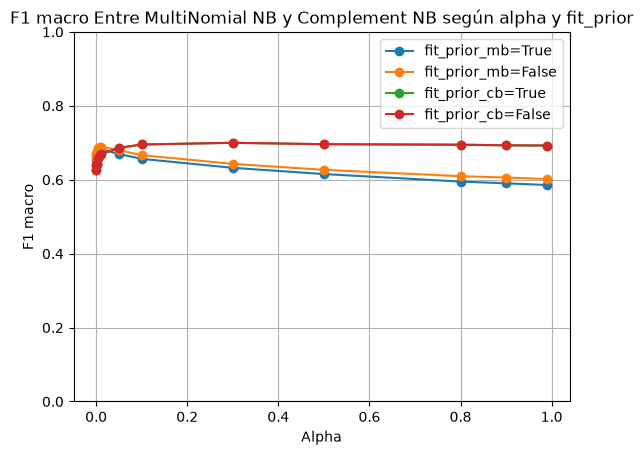

In [51]:
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

alphas = [0.99, 0.9, 0.8, 0.5, 0.3, 0.1, 0.05, 0.01, 0.009, 0.005, 0.001, 0.0009, 0.0005, 0.0001]
f1_scores = []
resultados = {"mb": {True: [], False: []}, "cb": {True: [], False: []}}


for fit_prior in [True, False]:
    for alpha in alphas:
        ##Primero vamos con Multinomial
        clf_mb = MultinomialNB(alpha=alpha, fit_prior=fit_prior)
        clf_mb.fit(X_train, y_train)
        X_test = tfidfvect.transform(newsgroups_test.data)
        y_test = newsgroups_test.target
        y_pred =  clf_mb.predict(X_test)
        f1_macro = f1_score(y_test, y_pred, average="macro")
        resultados["mb"][fit_prior].append(f1_macro)
        #luego aplicamos lo mismo para ComplementNB
        clf_cb = ComplementNB(alpha=alpha, fit_prior=fit_prior)
        clf_cb.fit(X_train, y_train)
        y_pred_cb =  clf_cb.predict(X_test)
        f1_macro_cb = f1_score(y_test, y_pred_cb, average="macro")
        resultados["cb"][fit_prior].append(f1_macro_cb)




fig, ax = plt.subplots()

ax.plot(alphas, resultados["mb"][True], marker="o", label="fit_prior_mb=True")
ax.plot(alphas, resultados["mb"][False], marker="o", label="fit_prior_mb=False")
ax.plot(alphas, resultados["cb"][True], marker="o", label="fit_prior_cb=True")
ax.plot(alphas, resultados["cb"][False], marker="o", label="fit_prior_cb=False")

ax.set_xlabel("Alpha")
ax.set_ylabel("F1 macro")
ax.set_title("F1 macro Entre MultiNomial NB y Complement NB según alpha y fit_prior")
ax.set_ylim(0, 1)
ax.grid(True)
ax.legend()

plt.show()

### Punto 4)

In [58]:
import numpy as np
from sklearn.metrics.pairwise import cosine_distances

# X_test tiene documentos en filas y términos en columnas.
# Al transponerla, cada fila representa un término.
X_termino_documento = X_test.T.tocsr()
palabras_vocabulario = tfidfvect.get_feature_names_out()

# Elegir manualmente palabras que estén en el vocabulario
palabras_elegidas = ["space", "game", "computer", "religion", "windows"]

indice_por_palabra = {
    palabra: indice
    for indice, palabra in enumerate(palabras_vocabulario)
}

palabras_no_encontradas = [
    palabra for palabra in palabras_elegidas
    if palabra not in indice_por_palabra
]

if palabras_no_encontradas:
    raise ValueError(
        f"Estas palabras no están en el vocabulario: {palabras_no_encontradas}"
    )

indices_palabras = [
    indice_por_palabra[palabra]
    for palabra in palabras_elegidas
]

# Distancia de cada palabra elegida con todos los términos
distancias_palabras = cosine_distances(
    X_termino_documento[indices_palabras],
    X_termino_documento
)

# Imprimir las cinco palabras más similares a cada palabra elegida
for fila, palabra in enumerate(palabras_elegidas):
    distancias = distancias_palabras[fila].copy()

    # Excluir la palabra comparada consigo misma
    distancias[indices_palabras[fila]] = np.inf

    indices_mas_similares = np.argsort(distancias)[:5]

    print(f"\nPalabra: {palabra}")
    for indice in indices_mas_similares:
        print(
            f"  {palabras_vocabulario[indice]} "
            f"(distancia: {distancias[indice]:.4f})"
        )


Palabra: space
  intergalactic (distancia: 0.7639)
  inflatable (distancia: 0.7650)
  velcro (distancia: 0.7930)
  brochure (distancia: 0.8005)
  tranquility (distancia: 0.8128)

Palabra: game
  espn (distancia: 0.6829)
  games (distancia: 0.7259)
  baseball (distancia: 0.7597)
  goal (distancia: 0.7616)
  hockey (distancia: 0.7617)

Palabra: computer
  shopper (distancia: 0.7821)
  visualisation (distancia: 0.8175)
  m13 (distancia: 0.8176)
  manchester (distancia: 0.8223)
  graphics (distancia: 0.8251)

Palabra: religion
  entrenched (distancia: 0.5806)
  proclamation (distancia: 0.6409)
  memetic (distancia: 0.6458)
  contracted (distancia: 0.6843)
  spam (distancia: 0.7213)

Palabra: windows
  dos (distancia: 0.6635)
  os (distancia: 0.7253)
  apps (distancia: 0.7691)
  run (distancia: 0.7743)
  microsoft (distancia: 0.8015)


**Interpretación.** Algunas palabras cercanas tienen sentido: `game` aparece junto a `games`, `baseball` y `hockey`; y `windows`, junto a `dos`, `os`, `apps` y `microsoft`. Es razonable, porque suelen aparecer en documentos sobre temas relacionados.

En otros casos, las asociaciones son menos claras. `space` queda cerca de `intergalactic`, pero también de `inflatable` y `velcro`; las palabras cercanas a `computer` y `religion` tampoco son fáciles de interpretar. Esto ocurre porque el método compara los documentos en los que aparece cada palabra, no sus significados directamente. Por eso puede encontrar asociaciones propias del corpus que no necesariamente son sinónimos.

En esta muestra, `game` y `windows` ofrecen ejemplos más claros, mientras que `computer` y `religion` muestran algunas limitaciones del método. No corresponde calcular F1 en este punto, ya que aquí no se clasifican documentos.